# Vodič kroz analizu: korekcija jeftinih senzora lebdećih čestica

Ova bilježnica korak po korak prolazi kroz cijeli projekt: odakle su podaci, kako su očišćeni,
koliko griješe nekorigirani senzori, kako rade metode korekcije i zašto ih testiramo baš ovako.
Uz svaki korak navedeni su i razlozi za odluke donesene u analizi.

**Kako je pokrenuti** (u terminalu, iz mape projekta):

```bash
cd pm-sensor-correction
uv run jupyter lab
```

Bilježnica koristi već preuzete i obrađene podatke iz mape `data/`, pa se cijela izvrši za nekoliko minuta.
Preuzimanje i učenje modela od nule rade skripte u mapi `src/` (vidi README).

**Sadržaj**
1. Pitanje i tijek analize
2. Podaci: izvori, odabir, preuzimanje i priprema
3. Vremensko usklađivanje
4. Koliko griješe nekorigirani senzori
5. Utjecaj vlažnosti i κ-Köhler korekcija
6. Metode korekcije i strojno učenje
7. Zašto validacija po područjima
8. Rezultati i provjere robusnosti
9. Što model zapravo koristi
10. Ograničenja
11. Pitanja i odgovori

## 1. Pitanje i tijek analize

**Pitanje:** koliko griješe jeftini optički senzori (većinom SDS011 iz mreže Sensor.Community) i koja metoda
korekcije ostaje pouzdana u područjima koja model nikad nije vidio, posebno tijekom epizoda saharske prašine,
dima i visoke vlažnosti?

**Tijek** (svaki korak je jedna skripta u `src/`):

| Korak | Skripta | Što radi |
|---|---|---|
| 1 | `find_pairs.py` | pronalazi senzore blizu EEA referentnih postaja (prometne ≤ 100 m, ostale ≤ 500 m) |
| 2 | `download_sensors.py` | preuzima dnevne datoteke senzora 2022.–2025. iz arhive Sensor.Community |
| 3 | `download_eea.py` | preuzima verificirane satne PM10 i PM2,5 s referentnih postaja |
| 4 | `process_sensors.py` | satni prosjeci, uklanjanje zasićenih vrijednosti i premještenih dana |
| 5 | `process_eea.py` | samo valjane vrijednosti, pretvorba u UTC |
| 6 | `check_time_alignment.py` | provjera vremenskog pomaka, neispravnih parova i parova s premalo podataka |
| 7 | `download_meteo.py` | ERA5 meteorologija i CAMS prašina/aerosoli preko Open-Meteo |
| 8 | `build_dataset.py` | spaja sve u jednu tablicu |
| 9 | `train_evaluate.py` | uči i testira sedam metoda korekcije (2024.–2025.) |
| 10 | `robustness.py` | provjere: CAMS reanaliza, drugačije grupiranje, test na sljedećoj godini, nesigurnost |
| 11 | `make_figures.py` | grafovi za README |

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Mapa projekta (bilježnica je u notebooks/)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import train_evaluate as te  # razdoblje, značajke i postavke modela
INTERIM, PROCESSED, RESULTS, FIG = ROOT / "data/interim", ROOT / "data/processed", ROOT / "results", ROOT / "figures"

# Iste boje kao u README grafovima
BOJE = {"ref": "#0b0b0b", "raw": "#898781", "kohler": "#eb6834", "gbm_weather": "#1baf7a",
        "gbm_no_sensor": "#eda100", "gbm_full": "#2a78d6", "grid": "#e1e0d9"}
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": BOJE["grid"], "axes.axisbelow": True})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Mapa projekta:", ROOT)

Mapa projekta: /var/home/pkb/Projects/pm-sensor-correction


## 2. Podaci: izvori, odabir, preuzimanje i priprema

Svi podaci su otvoreni i preuzimaju se automatski skriptama iz mape `src/`; za ponavljanje analize ne treba
nikakav korisnički račun. Ovaj odjeljak opisuje odakle podaci dolaze, kako su odabrani parovi jeftinih senzora i
referentnih postaja, kako su podaci preuzeti i kako su pripremljeni za analizu.

### 2.1 Izvori podataka

| Izvor | Što sadrži | Rezolucija | Uloga u analizi |
|---|---|---|---|
| [Sensor.Community](https://sensor.community/), arhiva | očitanja građanskih senzora PM10 i PM2,5 (većinom SDS011) | svakih ~2,5 min, točka | senzori koje korigiramo |
| [EEA Air Quality Download Service](https://eeadmz1-downloads-webapp.azurewebsites.net/) | satni PM10 i PM2,5 sa službenih postaja, verificirani (E1a) i neverificirani (E2a) | sat, točka | referenca („točna” vrijednost) |
| [Open-Meteo](https://open-meteo.com/): ERA5 | relativna vlažnost, temperatura, točka rosišta, visina graničnog sloja, vjetar, oborina, naoblaka, tlak | sat, mreža ~25 km | ulazi modela |
| [Open-Meteo](https://open-meteo.com/): CAMS | površinska prašina, aerosolna optička dubina, CO, modelirani PM10 i PM2,5 | sat, mreža ~10 km | ulazi modela i oznake epizoda |

- **Sensor.Community** je mreža građanske znanosti s desecima tisuća uređaja. Većina koristi optički brojač
  čestica SDS011, koji laserom broji čestice i iz broja procjenjuje masu PM2,5 i PM10. Mnogi uređaji uz njega
  imaju i senzor temperature i vlage (BME280, DHT22). Arhiva ima jednu CSV datoteku po senzoru i danu, s vremenom
  u UTC-u.
- **EEA** (Europska agencija za okoliš) prikuplja podatke službenih mreža država članica. Koristimo samo
  automatska mjerenja sa satnim vrijednostima. Verificirani podaci (E1a) konačni su podaci koje države predaju
  nakon provjere, a neverificirani (E2a) šalju se gotovo u stvarnom vremenu.
- **ERA5** je ECMWF-ova reanaliza meteoroloških uvjeta. Daje iste varijable na isti način za sve lokacije,
  uključujući one koje senzor ne mjeri (visina graničnog sloja, oborina).
- **CAMS** (Copernicus Atmosphere Monitoring Service) daje modelirane koncentracije aerosola i plinova; prašina
  iz CAMS-a ključna je za prepoznavanje epizoda saharske prašine. ERA5 i CAMS preuzimaju se preko besplatnog
  API-ja Open-Meteo. Za 2022.–2023. CAMS je reanaliza, što ima važnu posljedicu (odjeljak 2.6).

### 2.2 Odabir parova senzor–postaja

Polazište su dva popisa (`find_pairs.py`):
- **referentne postaje:** iz EEA metapodataka uzimamo postaje koje 2025. automatski mjere PM10 ili PM2,5;
- **jeftini senzori:** iz snimke mreže Sensor.Community (svi senzori aktivni u zadnja 24 sata, preuzeta
  6. 11. 2026.) uzimamo vanjske senzore lebdećih čestica; unutarnji su isključeni.

Za svaki senzor tražimo sve postaje unutar 500 m. Udaljenost se računa po velikoj kružnici (*haversine*), a za
brzinu se koristi prostorni indeks `BallTree`.

**Pravilo odabira:** senzor se uparuje s **prometnom** postajom samo ako je unutar **100 m**, a s **pozadinskom
ili industrijskom** unutar **500 m**. Uz prometnice se koncentracije mijenjaju od bloka do bloka, pa senzor 300 m
od prometne postaje mjeri drugačiji zrak; pozadinska postaja predstavlja šire područje. Tip postaje uzima se iz
EEA metapodataka. Sensor.Community objavljuje lokacije zaokružene na oko 100 m, pa su udaljenosti približne.

Referentne postaje s automatskim mjerenjem PM10/PM2,5 (EEA, 2025.): 4,602
Vanjski jeftini PM senzori u snimci Sensor.Community: 9,623


,parova,postaja,od toga s prometnom postajom
udaljenost do,,,
50 m,9,8,4
100 m,22,19,9
250 m,90,69,46
500 m,264,194,134


Odabrano pravilom (prometne ≤ 100 m, ostale ≤ 500 m): 139 parova, 130 senzora, 109 postaja, 19 zemalja


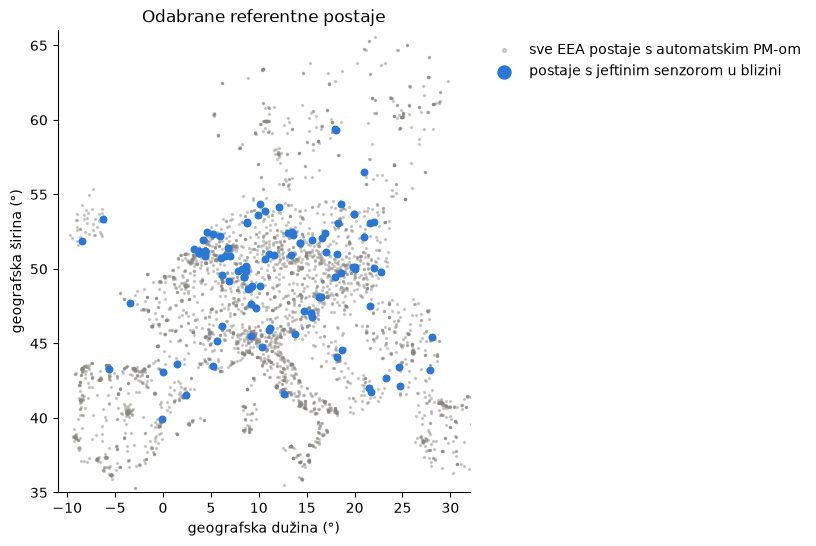

In [2]:
import find_pairs as fp

postaje = fp.load_reference_stations()
senzori = fp.load_low_cost_sensors()
print(f"Referentne postaje s automatskim mjerenjem PM10/PM2,5 (EEA, 2025.): {len(postaje):,}")
print(f"Vanjski jeftini PM senzori u snimci Sensor.Community: {len(senzori):,}")

parovi = pd.read_csv(INTERIM / "pairs.csv")          # svi parovi unutar 500 m
odabrani = pd.read_csv(INTERIM / "pairs_selected.csv")  # nakon pravila 100 m / 500 m
display(pd.DataFrame([{
    "udaljenost do": f"{g} m",
    "parova": int((parovi.distance_m <= g).sum()),
    "postaja": parovi.loc[parovi.distance_m <= g, "ref_station_code"].nunique(),
    "od toga s prometnom postajom": int(((parovi.distance_m <= g) & (parovi.ref_station_type == "traffic")).sum()),
} for g in (50, 100, 250, 500)]).set_index("udaljenost do"))
print(f"Odabrano pravilom (prometne ≤ 100 m, ostale ≤ 500 m): {len(odabrani)} parova, {odabrani.sensor_id.nunique()} "
      f"senzora, {odabrani.ref_station_code.nunique()} postaja, {odabrani.ref_country.nunique()} zemalja")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(postaje.lon, postaje.lat, s=2, color=BOJE["raw"], alpha=0.35, label="sve EEA postaje s automatskim PM-om")
o = odabrani.drop_duplicates("ref_station_code")
ax.scatter(o.ref_lon, o.ref_lat, s=22, color=BOJE["gbm_full"], label="postaje s jeftinim senzorom u blizini")
ax.set_xlim(-11, 32); ax.set_ylim(35, 66); ax.set_aspect(1 / np.cos(np.radians(50))); ax.grid(False)
ax.set_xlabel("geografska dužina (°)"); ax.set_ylabel("geografska širina (°)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1), markerscale=2); ax.set_title("Odabrane referentne postaje"); plt.show()

Strože pravilo za prometne postaje odbacuje većinu takvih parova: od 134 para s prometnom postajom unutar 500 m
samo ih je 9 unutar 100 m. Jedan senzor može biti blizu više postaja (i obrnuto), pa je osnovna jedinica analize
**par** senzor–postaja.

### 2.3 Preuzimanje

Svaki izvor ima svoju skriptu. Sve se mogu prekinuti i ponovno pokrenuti, jer preskaču već preuzete datoteke.

- **Sensor.Community** (`download_sensors.py`): za svaki odabrani senzor i svaki dan od 1. 1. 2022. do
  31. 12. 2025. preuzima se dnevna datoteka s adrese oblika
  `archive.sensor.community/2024/2024-04-08/2024-04-08_sds011_sensor_69437.csv.gz`. To je oko 190 000 zahtjeva
  (130 senzora × 1461 dan). Arhivu održavaju volonteri, pa skripta koristi samo 6 paralelnih veza i nakon pogreške
  čeka sve dulje. Dani za koje datoteka ne postoji (senzor tada nije radio) bilježe se u `missing.txt` da se ne
  traže ponovno.
- **EEA** (`download_eea.py`): API EEA-ina servisa za preuzimanje za svaku državu, onečišćujuću tvar i skup
  podataka vraća popis Parquet datoteka, po jednu za svako mjerno mjesto (*sampling point*). Preuzimaju se samo
  datoteke mjernih mjesta na odabranim postajama, i verificirane (E1a) i neverificirane (E2a).
- **Open-Meteo** (`download_meteo.py`): postaje se grupiraju u ćelije od 0,1°, a za svaku ćeliju traže se samo
  mjeseci u kojima postoje i podaci senzora i referentni podaci. Besplatni API ima ograničenja (600 zahtjeva u
  minuti, 5000 na sat i 10 000 na dan, a zahtjev dulji od dva tjedna broji se kao više njih), pa skripta sama
  pazi da ih ne prijeđe. Vrijeme se traži u UTC-u.

In [3]:
RAW = ROOT / "data/raw"
preuzeto = []
for izvor, mapa, uzorak in [("Sensor.Community: dnevne datoteke senzora", RAW / "sc", "*.csv.gz"),
                            ("EEA: referentni podaci (Parquet)", RAW / "eea", "*.parquet"),
                            ("Open-Meteo: ERA5 meteorologija", RAW / "meteo/weather", "*.json"),
                            ("Open-Meteo: CAMS", RAW / "meteo/airquality", "*.json")]:
    datoteke = list(mapa.rglob(uzorak))
    preuzeto.append({"izvor": izvor, "datoteka": len(datoteke),
                     "veličina (MB)": round(sum(f.stat().st_size for f in datoteke) / 1e6)})
display(pd.DataFrame(preuzeto).set_index("izvor"))
nema = sum(len((d / "missing.txt").read_text().split()) for d in (RAW / "sc").iterdir() if (d / "missing.txt").exists())
print(f"Dana bez datoteke u arhivi Sensor.Community (senzor tada nije radio): {nema:,}")

,datoteka,veličina (MB)
izvor,,
Sensor.Community: dnevne datoteke senzora,109906,546
EEA: referentni podaci (Parquet),283,204
Open-Meteo: ERA5 meteorologija,83,77
Open-Meteo: CAMS,83,54


Dana bez datoteke u arhivi Sensor.Community (senzor tada nije radio): 80,024


### 2.4 Priprema podataka

**Senzori** (`process_sensors.py`), za svaki senzor:
1. učitavaju se sve dnevne datoteke (vrijeme u UTC-u);
2. **provjera premještanja:** za svaki dan računa se medijan prijavljene lokacije; dani kad je senzor bio više od
   200 m od današnje lokacije izbacuju se, jer je tada mjerio negdje drugdje;
3. **fizikalni raspon:** negativne vrijednosti i vrijednosti ≥ 999 µg/m³ (zasićenje SDS011) brišu se;
4. **satni prosjeci:** SDS011 javlja vrijednost otprilike svakih 2,5 min (~24 puta na sat); zadržavaju se samo
   sati s barem 15 očitanja, tj. sati u kojima je senzor radio većinu vremena.

**Referentni podaci** (`process_eea.py`):
1. zadržavaju se samo vrijednosti koje EEA označava kao valjane (`Validity ≥ 1`), bez negativnih oznaka za
   nedostajuće vrijednosti;
2. EEA vremena su u lokalnom standardnom vremenu postaje (bez ljetnog računanja vremena, npr. UTC+1), pa se
   pretvaraju u UTC prema vremenskoj zoni iz metapodataka;
3. kad za isti sat postoje i verificirana i neverificirana vrijednost, prednost ima verificirana;
4. ako postaja ima više instrumenata za istu tvar (npr. zamijenjeni uređaj), njihove satne vrijednosti se
   usrednjavaju.

**Spajanje** (`check_time_alignment.py`, `build_dataset.py`):
1. provjerava se vremensko usklađivanje i traže se neispravni parovi (odjeljak 3); parovi s manje od 500
   zajedničkih sati ne mogu se provjeriti, pa se isključuju;
2. sati senzora i reference spajaju se po paru i satu;
3. dodaju se ERA5 i CAMS vrijednosti za ćeliju postaje u istom satu.

Koliko parova ostaje nakon svakog koraka:

In [4]:
sh = pd.read_parquet(INTERIM / "sensors_hourly.parquet", columns=["sensor_id", "time", "n_readings", "relocated_days_dropped"])
rh = pd.read_parquet(INTERIM / "reference_hourly.parquet", columns=["station_code", "time"])
sve = pd.read_parquet(PROCESSED / "matched.parquet", columns=["sensor_id", "ref_station_code", "time"])
ima_senzor = odabrani.sensor_id.isin(sh.sensor_id)
ima_ref = odabrani.ref_station_code.isin(rh.station_code)
par = ["sensor_id", "ref_station_code"]
display(pd.DataFrame({"parova": {
    "odabrani pravilom udaljenosti": len(odabrani),
    "senzor ima podatke za 2022.–2025.": int(ima_senzor.sum()),
    "i postaja ima referentne podatke": int((ima_senzor & ima_ref).sum()),
    "barem 500 zajedničkih sati": len(pd.read_csv(INTERIM / "time_alignment.csv")),
    "bez neispravnih (r < 0,3)": sve.groupby(par).ngroups,
    f"s podacima u {te.YEARS[0]}.–{te.YEARS[-1]}.": sve[sve.time.dt.year.isin(te.YEARS)].groupby(par).ngroups,
}}))
premjesteni = sh.groupby("sensor_id").relocated_days_dropped.first()
print(f"Satni podaci senzora: {len(sh):,} sati, medijan {sh.n_readings.median():.0f} očitanja po satu; "
      f"{(premjesteni > 0).sum()} senzora imalo je dane na drugoj lokaciji ({premjesteni.sum():,} dana uklonjeno)")
print(f"Satni referentni podaci: {len(rh):,} sati na {rh.station_code.nunique()} postaja")

,parova
odabrani pravilom udaljenosti,139
senzor ima podatke za 2022.–2025.,110
i postaja ima referentne podatke,81
barem 500 zajedničkih sati,74
"bez neispravnih (r < 0,3)",68
s podacima u 2024.–2025.,65


Satni podaci senzora: 2,082,820 sati, medijan 24 očitanja po satu; 5 senzora imalo je dane na drugoj lokaciji (2,088 dana uklonjeno)
Satni referentni podaci: 2,161,117 sati na 79 postaja


Najviše parova otpada prije same analize: popis senzora je snimka iz studenog 2026., pa dio senzora u
2022.–2025. još nije radio, a za dio postaja servis za preuzimanje nije vratio satne podatke za to razdoblje.

### 2.5 Konačna tablica

Glavna tablica `matched.parquet` ima jedan redak po **satu, senzoru i postaji**: očitanje senzora
(`pm10_lc`, `pm25_lc`, „lc” = *low-cost*), referentnu vrijednost (`pm10_ref`, `pm25_ref`),
ERA5 meteorologiju i CAMS polja (prašina `dust`, aerosolna optička dubina, CO, modelirani PM).

Modeli se uče i testiraju na razdoblju **2024.–2025.**; zašto ne i ranije, objašnjeno je u odjeljku 2.6.

In [5]:
m = pd.read_parquet(PROCESSED / "matched.parquet")
print(f"Preuzeto: {len(m):,} usporednih sati, {m.time.min():%Y-%m-%d} do {m.time.max():%Y-%m-%d}")
m = m[m.time.dt.year.isin(te.YEARS)]
print(f"Za analizu ({te.YEARS[0]}.–{te.YEARS[-1]}.): {len(m):,} sati | {m.sensor_id.nunique()} senzora | "
      f"{m.ref_station_code.nunique()} postaja | {m.ref_country.nunique()} zemalja")
m[["time", "sensor_id", "ref_station_name", "pm10_lc", "pm10_ref", "pm25_lc", "pm25_ref",
   "relative_humidity_2m", "dust"]].sample(5, random_state=1)

Preuzeto: 1,274,084 usporednih sati, 2022-01-01 do 2025-12-31
Za analizu (2024.–2025.): 771,942 sati | 65 senzora | 54 postaja | 13 zemalja


,time,sensor_id,ref_station_name,pm10_lc,pm10_ref,pm25_lc,pm25_ref,relative_humidity_2m,dust
669208,2024-03-06 01:00:00+00:00,69437,Stuttgart-Bad Cannstatt,23.52,14.10,10.89,11.00,92,0.00
598193,2025-03-08 18:00:00+00:00,56991,"Cieszyn, ul. Chopina",78.92,88.60,41.37,NaN,80,7.00
798033,2024-08-22 00:00:00+00:00,58661,"Przemyśl, ul. Grunwaldzka",23.30,20.10,20.34,16.20,90,0.00
202600,2024-08-19 03:00:00+00:00,77732,"""42R834 - BOOM""",0.00,11.80,0.00,7.77,92,1.00
566683,2025-03-29 21:00:00+00:00,18754,Konstanz,5.91,10.20,3.96,7.40,81,0.00


In [6]:
parovi = m.drop_duplicates(["sensor_id", "ref_station_code"])
pregled = parovi.groupby("ref_country").agg(parova=("sensor_id", "size"),
                                            postaja=("ref_station_code", "nunique"),
                                            prometnih=("ref_station_type", lambda s: (s == "traffic").sum()))
sati = m.groupby("ref_country").size().rename("sati")
pregled.join(sati).sort_values("sati", ascending=False)

,parova,postaja,prometnih,sati
ref_country,,,,
Germany,27,21,2,345288
Belgium,13,9,1,144523
Poland,7,7,0,84019
Austria,5,5,0,49050
France,3,3,0,47998
North Macedonia,2,1,0,33300
Sweden,1,1,0,16226
Netherlands,2,2,0,15813
Czechia,1,1,0,14450


### 2.6 Zašto samo 2024.–2025.

Za 2022. i 2023. Open-Meteo daje **CAMS reanalizu**, a ne prognozu. Reanaliza naknadno ugrađuje (asimilira)
mjerenja s EEA postaja, među njima i s naših referentnih postaja. U tim je godinama CAMS dakle djelomično
„vidio” točan odgovor. Od 2024. vrijednosti su **arhivirane prognoze**, kakve bi sustav imao i u stvarnom vremenu.

To se vidi u podacima. Za svaku postaju i tromjesečje računamo korelaciju s referencom i uzimamo medijan
po postajama. Do kraja 2023. CAMS na mreži od 10 km prati svaku postaju jednako dobro kao jeftini senzor
koji stoji uz nju, što je moguće samo ako je CAMS tu postaju već „vidio”. U siječnju 2024. korelacija
CAMS-a naglo pada, a korelacija senzora ostaje ista.

,"r: CAMS PM2,5 – referenca (medijan po postajama)","r: senzor PM2,5 – referenca (medijan po postajama)"
godina,,
2022,0.87,0.83
2023,0.88,0.82
2024,0.67,0.81
2025,0.68,0.83


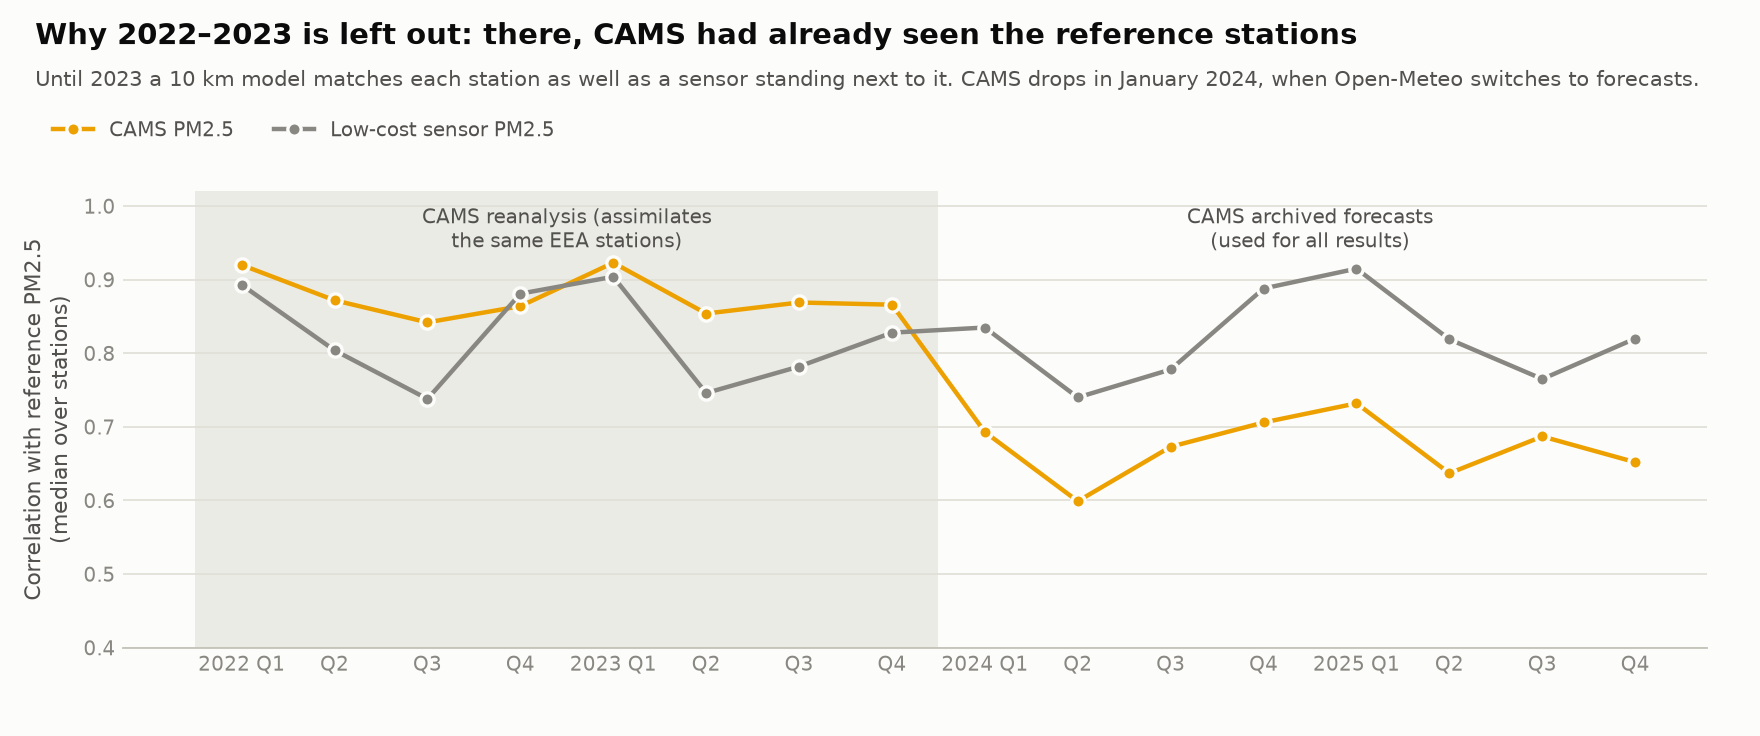

In [7]:
cc = pd.read_csv(RESULTS / "cams_check.csv")
po_godini = cc.assign(godina=cc.quarter.str[:4]).groupby("godina")[["r_pm25_cams", "r_pm25_lc"]].mean()
display(po_godini.rename(columns={"r_pm25_cams": "r: CAMS PM2,5 – referenca (medijan po postajama)",
                                  "r_pm25_lc": "r: senzor PM2,5 – referenca (medijan po postajama)"}).round(2))
display(Image(filename=str(FIG / "cams_check_light.png"), width=900))

Posljedica se vidi i na modelima. Kad iste metode učimo i testiramo na 2022.–2023., kontrolni model **bez
senzora** (samo CAMS i meteorologija) u satima prašine ima RMSE za PM10 od samo 12,7 µg/m³, a model sa
senzorom 13,1. U 2024.–2025. isti model bez senzora ima 21,4 µg/m³. Model koji ništa ne zna o
mjestu mjerenja ne bi smio biti toliko dobar; upravo je to otkrilo problem. Prva verzija projekta koristila je
sve četiri godine i zato je precijenila CAMS. Sada se svi modeli uče i testiraju samo na 2024.–2025.

## 3. Vremensko usklađivanje

Sensor.Community bilježi vrijeme u UTC-u, a EEA podaci su u lokalnom standardnom vremenu postaje.
Nakon pretvorbe u UTC provjerili smo usklađenost **unakrsnom korelacijom**: pomičemo referentni niz za
−3 do +3 sata i gledamo pri kojem je pomaku korelacija sa senzorom najveća. Ako je sve ispravno, najbolji pomak je 0.

In [8]:
pomaci = pd.read_csv(INTERIM / "time_alignment.csv")
print("Najbolji pomak (h) → broj parova:", pomaci.best_lag_h.value_counts().sort_index().to_dict())
pomaci[pomaci.best_lag_h != 0].sort_values("n_hours", ascending=False)

Najbolji pomak (h) → broj parova: {-2: 3, -1: 6, 0: 63, 1: 1, 2: 1}


,sensor_id,station,country,best_lag_h,r_at_0,r_best,n_hours
53,17414,AT30603,Austria,1,0.02,0.02,29558
26,79478,CZ0ZVMZ,Czechia,-2,0.66,0.70,20719
30,52764,BA0032A,Bosnia and Herzegovina,-1,0.81,0.82,19015
64,86471,DEHB001,Germany,-2,0.64,0.68,15080
21,45690,AT60172,Austria,-1,0.57,0.58,9163
44,45206,PL0620A,Poland,-1,0.59,0.61,6838
6,35646,IT2262A,Italy,-1,0.72,0.74,6106
65,94953,AT60118,Austria,-1,0.58,0.61,4254
49,19814,DEHB001,Germany,-2,0.53,0.58,2413
72,91020,ES1877A,Spain,2,0.69,0.71,635


Kod nekoliko postaja najbolji pomak je −1 ili −2 h. Provjerili smo ljeto i zimu odvojeno: pomak je isti
u oba godišnja doba, dakle **nije** riječ o ljetnom računanju vremena, nego o postajama koje sat označavaju
drugačije (npr. krajem umjesto početkom sata). Te postaje dobile su stalni ispravak (`station_time_offsets.csv`).

Primjer krivulje za postaju DEHB001 (Bremen), koja mjeri samo PM10:

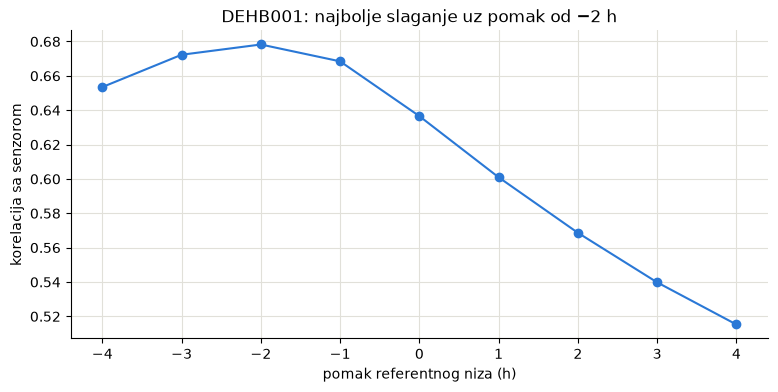

In [9]:
sens = pd.read_parquet(INTERIM / "sensors_hourly.parquet").set_index(["sensor_id", "time"])
ref = pd.read_parquet(INTERIM / "reference_hourly.parquet").set_index(["station_code", "time"])
s, r = sens.loc[86471], ref.loc["DEHB001"]
lagovi = range(-4, 5)
korelacije = []
for lag in lagovi:
    pomaknut = r["pm10_ref"].copy()
    pomaknut.index = pomaknut.index + pd.Timedelta(hours=lag)
    par = pd.concat([s["pm10_lc"], pomaknut], axis=1, join="inner").dropna()
    korelacije.append(par.iloc[:, 0].corr(par.iloc[:, 1]))
plt.plot(list(lagovi), korelacije, marker="o", color=BOJE["gbm_full"])
plt.xlabel("pomak referentnog niza (h)"); plt.ylabel("korelacija sa senzorom")
plt.title("DEHB001: najbolje slaganje uz pomak od −2 h"); plt.show()

Isti test otkriva i **neispravne parove**: ako senzor ni uz jedan pomak ne prati referencu (r < 0,3),
ili je pokvaren ili ne mjeri isti zrak. Takvih je 6 i isključeni su. Isključeni su i parovi s manje od
500 zajedničkih sati, jer se za njih ova provjera ne može napraviti (`excluded_pairs.csv`).

In [10]:
isklj = pd.read_csv(INTERIM / "excluded_pairs.csv")
print(isklj.reason.value_counts().to_string())
isklj[isklj.reason.str.startswith("r <")]

reason
under 500 h overlap, cannot be checked    65
r < 0.3                                    6


,sensor_id,station,reason
0,80177,BETR702,r < 0.3
1,29576,DESH053,r < 0.3
2,22595,BETR834,r < 0.3
3,90258,FR12042,r < 0.3
4,17414,AT30603,r < 0.3
5,16472,DEBE034,r < 0.3


## 4. Koliko griješe nekorigirani senzori

Prvo osnovne mjere za sve sate zajedno:
- **R²**: koliki dio varijacije referentne vrijednosti senzor objašnjava (1 = savršeno; može biti i negativan
  kad je pogreška veća od same varijacije),
- **RMSE**: korijen srednje kvadratne pogreške u µg/m³,
- **bias**: prosječna razlika senzor − referenca.

In [11]:
def mjere(senzor, referenca):
    d = pd.concat([senzor, referenca], axis=1).dropna()
    x, y = d.iloc[:, 0], d.iloc[:, 1]
    return {"sati": len(d), "R2": 1 - ((x - y) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            "RMSE": np.sqrt(((x - y) ** 2).mean()), "bias": (x - y).mean(), "omjer senzor/ref": x.mean() / y.mean()}

tab = pd.DataFrame({"PM2,5": mjere(m.pm25_lc, m.pm25_ref), "PM10": mjere(m.pm10_lc, m.pm10_ref)}).T
tab["sati"] = tab["sati"].astype(int)
tab

,sati,R2,RMSE,bias,omjer senzor/ref
"PM2,5",666107,0.46,8.97,-4.57,0.57
PM10,737154,0.02,17.81,-4.95,0.72


Senzor u prosjeku pokazuje oko 40 % premalo PM2,5, a PM10 je još lošiji. Razlog za PM10 vidi se kad
podijelimo sate prema tome **koliko je zrak krupan**, mjereno referentnim omjerom PM2,5/PM10
(nizak omjer = puno krupnih čestica, tipično za prašinu):

In [12]:
d = m[(m.pm10_ref > 10) & (m.pm25_ref > 0)].dropna(subset=["pm10_lc"]).copy()
d["omjer_ref"] = d.pm25_ref / d.pm10_ref
d["razred"] = pd.cut(d.omjer_ref, [0, 0.3, 0.45, 0.6, 0.75, 0.9, 1.01])
tablica = d.groupby("razred", observed=True).apply(
    lambda g: pd.Series({"sati": len(g), "senzor vidi (% PM10)": 100 * (g.pm10_lc / g.pm10_ref).median()}))
tablica["sati"] = tablica["sati"].astype(int)
tablica

,sati,senzor vidi (% PM10)
razred,,
"(0.0, 0.3]",23826,23.41
"(0.3, 0.45]",77182,34.25
"(0.45, 0.6]",110144,46.25
"(0.6, 0.75]",109619,61.80
"(0.75, 0.9]",81345,85.73
"(0.9, 1.01]",16772,114.11


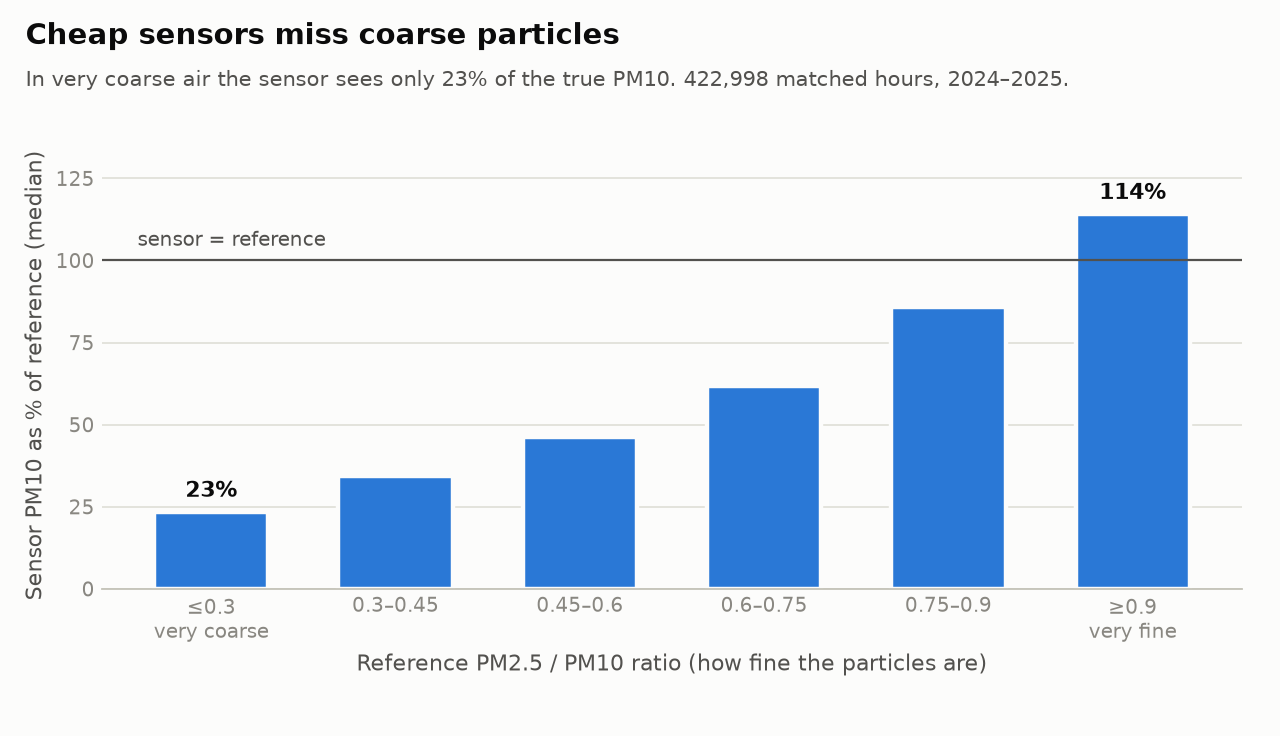

In [13]:
display(Image(filename=str(FIG / "coarse_underestimation_light.png"), width=750))

**Fizikalno objašnjenje:** SDS011 je optički brojač koji vidi uglavnom čestice manje od ~2,5 µm, a PM10 iz
tog broja procjenjuje uz pretpostavljenu raspodjelu veličina. Kad dominiraju krupne čestice (pustinjska prašina,
prašina s ceste), ta pretpostavka ne vrijedi i senzor drastično podcjenjuje PM10.

## 5. Utjecaj vlažnosti i κ-Köhler korekcija

Čestice upijaju vodu i pri visokoj vlažnosti narastu, pa ih optički senzor „vidi” kao veće i brojnije.
Pogledajmo prosječnu pogrešku nekorigiranog PM10 po razredima relativne vlažnosti (ERA5):

In [14]:
razredi = pd.cut(m.relative_humidity_2m, [0, 50, 60, 70, 80, 90, 95, 101], right=False)
(m.pm10_lc - m.pm10_ref).groupby(razredi, observed=True).agg(["mean", "count"]).rename(
    columns={"mean": "prosječna pogreška PM10 (µg/m³)", "count": "sati"})

,prosječna pogreška PM10 (µg/m³),sati
relative_humidity_2m,,
"[0, 50)",-12.43,65688
"[50, 60)",-9.84,65679
"[60, 70)",-8.34,97238
"[70, 80)",-6.57,135762
"[80, 90)",-3.84,181620
"[90, 95)",-0.99,110095
"[95, 101)",3.97,81072


U suhom zraku senzor podcjenjuje, u vrlo vlažnom precjenjuje. Standardna fizikalna korekcija je
**κ-Köhlerova teorija higroskopnog rasta**: očitanje dijelimo faktorom rasta

```latex
f(a_w) = 1 + \frac{\kappa / 1{,}65}{1/a_w - 1}, \qquad a_w = \frac{RH}{100}
```

gdje je κ higroskopnost čestica (0 = ne upijaju vodu; ~0,2–0,6 za tipični urbani aerosol), a 1,65 gustoća
suhih čestica u g/cm³. κ smo birali na podacima za učenje: za PM10 ispao je 0,1–0,2, a za PM2,5 čak 0,
što znači da kod PM2,5 vlažnost nije glavni izvor pogreške (pa je za PM2,5 κ-Köhler isto što i
linearna korekcija).

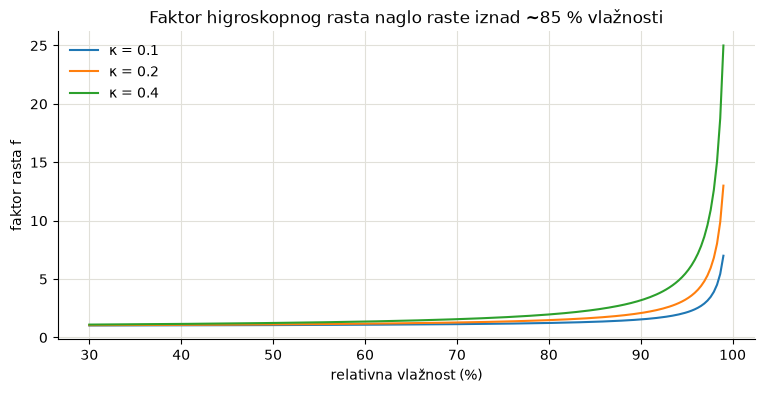

In [15]:
rh = np.linspace(30, 99, 200)
for kappa in (0.1, 0.2, 0.4):
    f = 1 + (kappa / 1.65) / (1 / (rh / 100) - 1)
    plt.plot(rh, f, label=f"κ = {kappa}")
plt.xlabel("relativna vlažnost (%)"); plt.ylabel("faktor rasta f"); plt.legend(frameon=False)
plt.title("Faktor higroskopnog rasta naglo raste iznad ~85 % vlažnosti"); plt.show()

## 6. Metode korekcije i strojno učenje

Usporedili smo sedam metoda, od najjednostavnije do najsloženije:

| Metoda | Opis |
|---|---|
| nekorigirano | vrijednost senzora |
| linearna | `ref = a + b × senzor` |
| linearna + vlažnost | dodaje relativnu vlažnost i temperaturu |
| κ-Köhler | dijeli s faktorom higroskopnog rasta pa linearno skalira |
| ML: senzor + meteorologija | LightGBM s oba kanala senzora, njihovim omjerom, ERA5 meteorologijom i dobom dana/godine |
| ML: CAMS + meteorologija, bez senzora | kontrolni model: pokazuje koliko CAMS postiže sam |
| ML: senzor + meteorologija + CAMS | sve gore plus CAMS prašina, AOD, CO i modelirani PM |

**LightGBM** (gradient boosting) gradi stotine malih stabala odlučivanja; svako ispravlja pogreške prethodnih.
Dobro hvata nelinearne odnose, npr. „kad je CAMS prašina visoka, a senzor vidi malo PM10, prava vrijednost je
mnogo viša”. Postavke modela:

In [16]:
print("Postavke LightGBM-a:", te.GBM_PARAMS)
print("Meteorološki ulazi:", te.WEATHER)
print("CAMS ulazi:", te.CAMS)

Postavke LightGBM-a: {'n_estimators': 600, 'learning_rate': 0.05, 'num_leaves': 63, 'min_child_samples': 200, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'verbose': -1}
Meteorološki ulazi: ['relative_humidity_2m', 'temperature_2m', 'dew_point_2m', 'boundary_layer_height', 'wind_speed_10m', 'precipitation', 'cloud_cover', 'surface_pressure']
CAMS ulazi: ['dust', 'aerosol_optical_depth', 'carbon_monoxide', 'pm10_cams', 'pm25_cams']


**Važno:** oznake epizoda (prašina, dim, vlažno) koriste referentni omjer PM2,5/PM10, ali **nikad nisu ulaz
modela**. Model vidi samo ono što bi imao i u stvarnoj primjeni: senzor, meteorologiju i CAMS prognoze.

## 7. Zašto validacija po područjima

Kad bismo sate nasumično dijelili na skup za učenje i skup za testiranje, model bi učio i testirao se na
**istim postajama** (čak na susjednim satima istog senzora). Rezultat bi izgledao bolje nego što jest,
jer bi model zapamtio posebnosti pojedinog senzora i lokacije.

Zato koristimo **unakrsnu validaciju grupiranu po područjima** (`GroupKFold`): postaje udaljene manje od
50 km uvijek su zajedno, ili u skupu za učenje ili u skupu za testiranje. Tako model ne može „posuditi”
mjerenje susjedne postaje iz istog grada u istom satu. To odgovara stvarnom pitanju: *koliko dobro radi u
novom gradu?*

Pokus na uzorku od 200 000 sati pokazuje razliku (traje oko minute):

In [17]:
from sklearn.model_selection import GroupKFold, KFold
import lightgbm as lgb

df = te.add_features(m).dropna(subset=["relative_humidity_2m", "dust", "pm10_lc", "pm10_ref"])
df["group"] = te.area_groups(df)  # postaje unutar 50 km zajedno
uzorak = df.sample(200_000, random_state=0).reset_index(drop=True)
znacajke = ["pm25_lc", "pm10_lc", "lc_ratio", "sensor_type"] + te.TIME + te.WEATHER + te.CAMS
params = {**te.GBM_PARAMS, "n_estimators": 200}

def rmse_cv(podjela, grupe=None):
    pogreske = []
    for tr, ts in podjela.split(uzorak, groups=grupe):
        g = lgb.LGBMRegressor(**params).fit(uzorak.loc[tr, znacajke], uzorak.loc[tr, "pm10_ref"])
        p = g.predict(uzorak.loc[ts, znacajke])
        pogreske.append(np.sqrt(np.mean((p - uzorak.loc[ts, "pm10_ref"]) ** 2)))
    return np.mean(pogreske)

nasumicno = rmse_cv(KFold(5, shuffle=True, random_state=0))
po_podrucjima = rmse_cv(GroupKFold(5), uzorak["group"])
print(f"RMSE PM10, nasumična podjela sati:   {nasumicno:.1f} µg/m³  (previše optimistično)")
print(f"RMSE PM10, podjela po područjima:    {po_podrucjima:.1f} µg/m³  (pošteno za novi grad)")

RMSE PM10, nasumična podjela sati:   8.6 µg/m³  (previše optimistično)
RMSE PM10, podjela po područjima:    11.1 µg/m³  (pošteno za novi grad)


Nasumična podjela daje primjetno manju pogrešku, ali to je iluzija: model je već „vidio” te postaje.
Svi rezultati projekta zato su iz podjele po područjima.

## 8. Rezultati

Pogreška (RMSE, µg/m³) svake metode u područjima koja model nije vidio, ukupno i po vrsti sati:

In [18]:
met = pd.read_csv(RESULTS / "metrics.csv")
nazivi = {"raw": "nekorigirano", "linear": "linearna", "linear_rh": "linearna + vlaga", "kohler": "κ-Köhler",
          "gbm_weather": "ML: senzor + meteo", "gbm_no_sensor": "ML: CAMS + meteo (bez senzora)",
          "gbm_full": "ML: senzor + meteo + CAMS"}
skupovi = {"all": "svi sati", "dust": "prašina", "smoke": "dim", "humid": "vlažno (≥ 85 %)", "normal": "ostalo"}
t = met.pivot_table(index=["target", "subset"], columns="method", values="rmse")[list(nazivi)]
t = t.rename(columns=nazivi).rename(index=skupovi, level=1).rename(index={"pm10": "PM10", "pm25": "PM2,5"}, level=0)
t.round(1)

method                  nekorigirano  linearna  linearna + vlaga  κ-Köhler  \
target subset                                                                
PM10   svi sati                17.80     14.60             14.40     13.60   
       prašina                 35.10     32.90             30.90     30.00   
       vlažno (≥ 85 %)         20.80     14.60             14.40     13.40   
       ostalo                  15.30     14.40             14.20     13.40   
       dim                     20.30     11.60             11.20      9.50   
PM2,5  svi sati                 9.00      7.80              7.70      7.80   
       prašina                 12.50      9.10              9.50      9.10   
       vlažno (≥ 85 %)          9.20      8.40              8.20      8.40   
       ostalo                   8.80      7.40              7.30      7.40   
       dim                     10.40     10.20              9.90     10.20   

method                  ML: senzor + meteo  ML: CAMS + meteo (bez senzora)  \
target subset                                                                
PM10   svi sati                      12.60                           13.40   
       prašina                       21.90                           21.40   
       vlažno (≥ 85 %)               12.20                           12.90   
       ostalo                        12.70                           13.70   
       dim                            8.60                           10.70   
PM2,5  svi sati                       6.90                            7.90   
       prašina                        6.40                            8.20   
       vlažno (≥ 85 %)                7.50                            8.30   
       ostalo                         6.60                            7.60   
       dim                            7.00                            8.00   

method                  ML: senzor + meteo + CAMS  
target subset                                      
PM10   svi sati                             12.10  
       prašina                              18.10  
       vlažno (≥ 85 %)                      11.70  
       ostalo                               12.30  
       dim                                   8.00  
PM2,5  svi sati                              6.30  
       prašina                               5.50  
       vlažno (≥ 85 %)                       6.70  
       ostalo                                6.10  
       dim                                   6.20

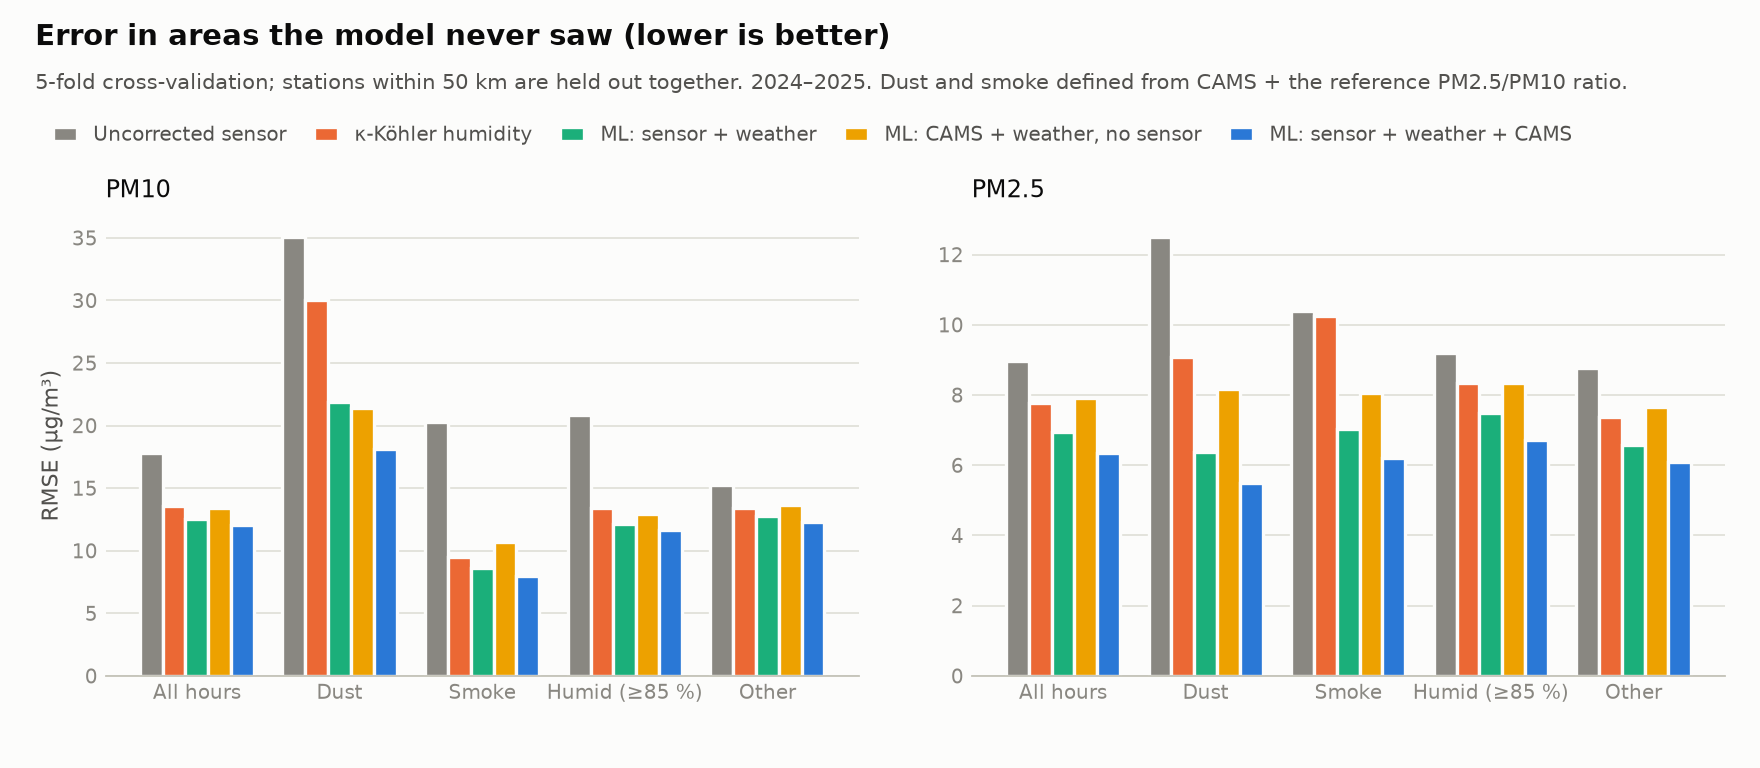

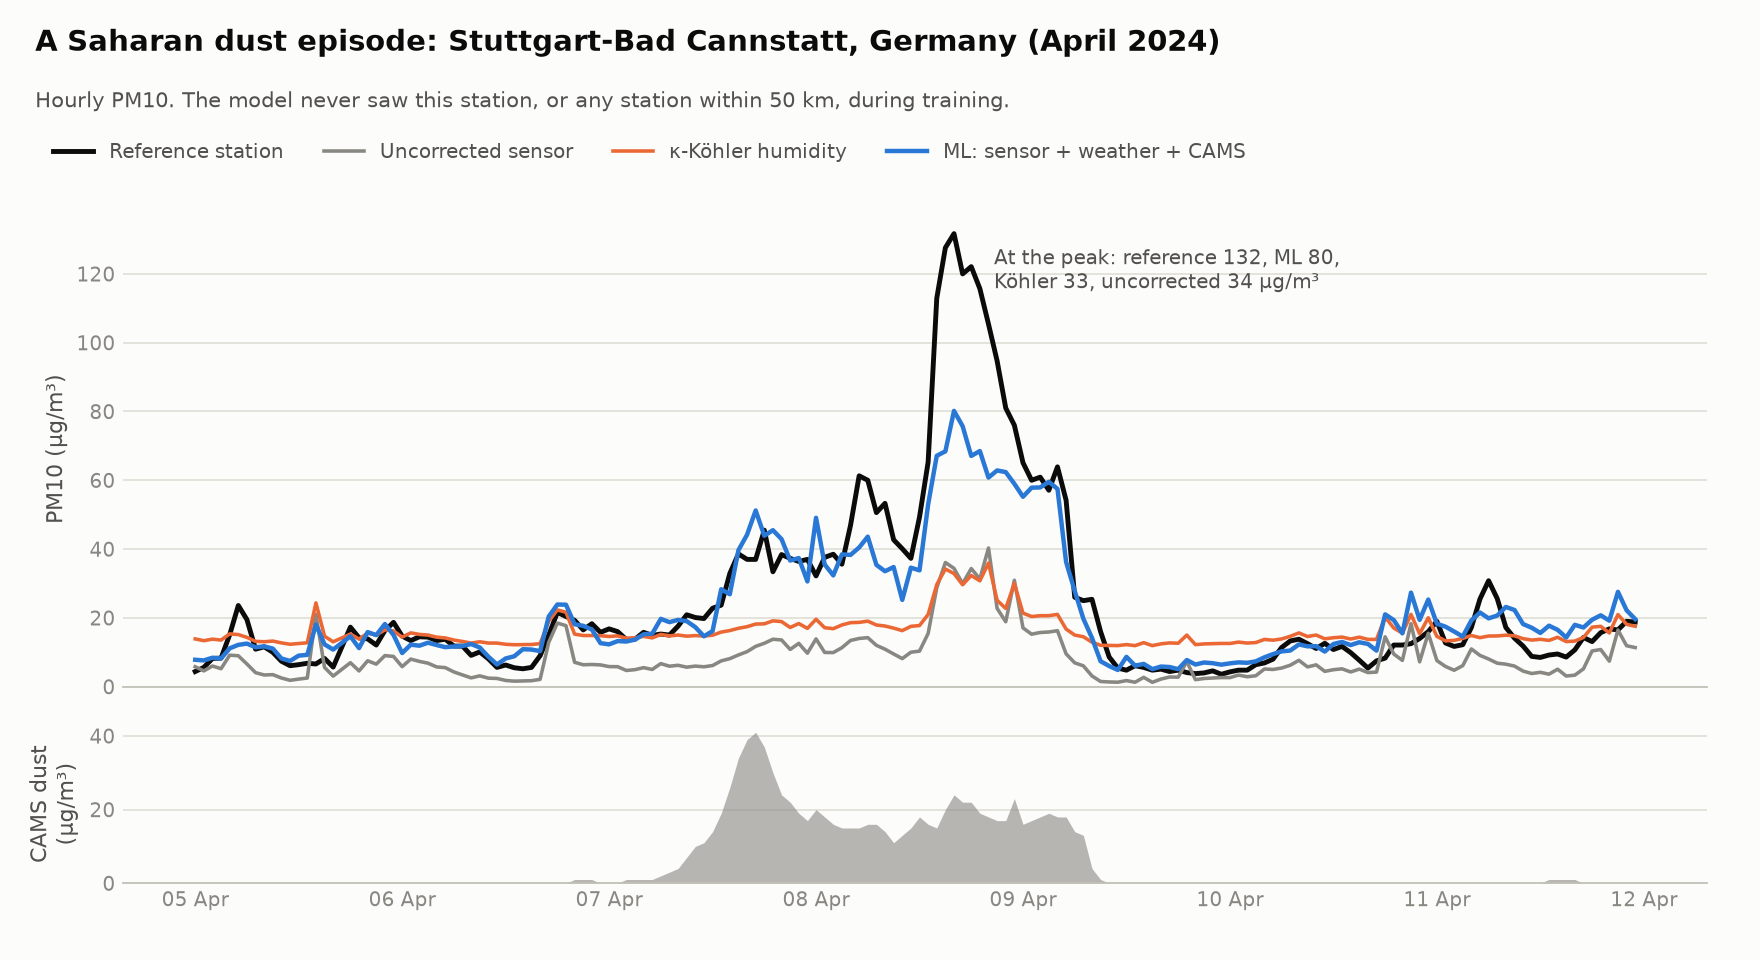

In [19]:
display(Image(filename=str(FIG / "rmse_by_condition_light.png"), width=900))
display(Image(filename=str(FIG / "dust_episode_light.png"), width=900))

**Kako čitati rezultate:**
- U epizodama prašine RMSE za PM10 pada s 35,1 (nekorigirano) na 30,0 (κ-Köhler) i na
  **18,1 µg/m³** s modelom koji koristi CAMS prognozu prašine. Korekcija vlažnosti ne može nadoknaditi
  čestice koje senzor uopće ne vidi.
- Kontrolni model **bez senzora** lošiji je u svim uvjetima, posebno za PM2,5 (7,9 naspram 6,3 µg/m³):
  senzor nosi lokalnu informaciju koju CAMS na mreži od ~10 km nema.
- Rezultat za dim temelji se na samo 673 sati i najmanje je siguran.

### Provjere robusnosti

Glavni rezultat provjeren je na nekoliko načina (`src/robustness.py`): s jednom skupinom po postaji umjesto
po području, s učenjem na 2024. i testom na 2025., te na godinama s CAMS reanalizom (za usporedbu).

In [20]:
rob = pd.read_csv(RESULTS / "robustness.csv")
provjere = {"main": "glavni rezultat", "station_groups": "jedna skupina po postaji",
            "train_2024_test_2025": "učenje 2024. → test 2025.",
            "reanalysis_years_2022_23": "2022.–2023. (CAMS reanaliza)"}
r = rob[rob.check.isin(provjere)].pivot_table(index="check", columns=["target", "subset", "method"], values="rmse")
pd.DataFrame({
    "PM10 prašina: κ-Köhler": r[("pm10", "dust", "kohler")],
    "PM10 prašina: ML bez senzora": r[("pm10", "dust", "gbm_no_sensor")],
    "PM10 prašina: ML puni": r[("pm10", "dust", "gbm_full")],
    "PM2,5 svi sati: ML bez senzora": r[("pm25", "all", "gbm_no_sensor")],
    "PM2,5 svi sati: ML puni": r[("pm25", "all", "gbm_full")],
}).rename(index=provjere).loc[list(provjere.values())].round(1)

,PM10 prašina: κ-Köhler,PM10 prašina: ML bez senzora,PM10 prašina: ML puni,"PM2,5 svi sati: ML bez senzora","PM2,5 svi sati: ML puni"
check,,,,,
glavni rezultat,30.00,21.40,18.10,7.90,6.30
jedna skupina po postaji,29.90,20.50,16.90,7.60,6.00
učenje 2024. → test 2025.,31.40,27.40,24.90,8.70,6.70
2022.–2023. (CAMS reanaliza),22.60,12.70,13.10,8.30,6.20


- Uz jednu skupinu po postaji pogreška je nešto manja, jer testna postaja tada može imati susjeda iz
  istog grada u skupu za učenje. Grupiranje po područjima zato je stroži i pošteniji test.
- Kad model učimo samo na 2024. i testiramo na 2025., puni model je i dalje najbolji u svim uvjetima,
  ali mu je prednost u prašini manja (PM10: κ-Köhler 31,4, puni model 24,9 µg/m³), jer
  jedna godina ima malo epizoda prašine za učenje.
- **Nesigurnost:** kad područja nasumično ponovno uzorkujemo (*cluster bootstrap*, 2000 puta), puni model u
  prašini smanjuje RMSE za PM10 u odnosu na κ-Köhler za 40 %, s 95 %-tnim intervalom 34–50 %.
- **Lažne uzbune CAMS-a:** u 1947 sati CAMS je predvidio prašinu, ali zrak na postaji nije bio krupan.
  Puni model tada prosječno griješi samo 1,5 µg/m³, a RMSE mu je 11,5 (κ-Köhler 15,4).
  Model dakle ne „dodaje prašinu” slijepo kad je CAMS najavi.

## 9. Što model zapravo koristi

Važnost značajki (*gain*: koliko svaka značajka ukupno smanjuje pogrešku u stablima) za PM10 model,
naučen na istom uzorku:

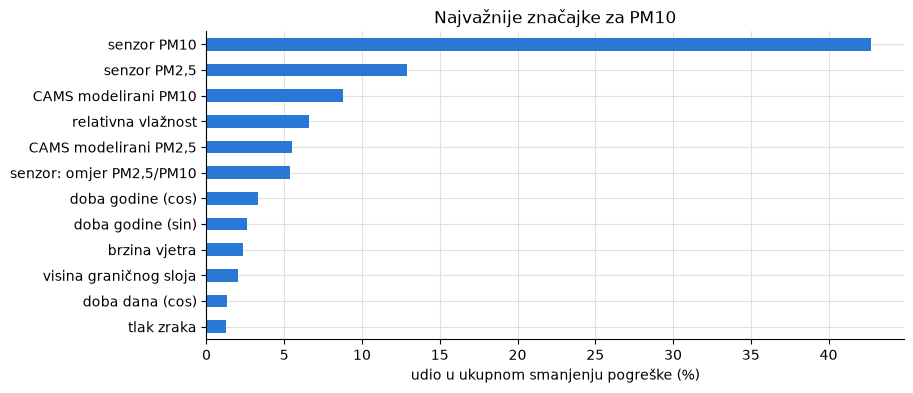

In [21]:
g = lgb.LGBMRegressor(**params, importance_type="gain").fit(uzorak[znacajke], uzorak["pm10_ref"])
nazivi_hr = {"pm10_cams": "CAMS modelirani PM10", "pm25_cams": "CAMS modelirani PM2,5", "pm25_lc": "senzor PM2,5",
             "pm10_lc": "senzor PM10", "lc_ratio": "senzor: omjer PM2,5/PM10", "relative_humidity_2m": "relativna vlažnost",
             "temperature_2m": "temperatura", "dew_point_2m": "točka rosišta", "boundary_layer_height": "visina graničnog sloja",
             "wind_speed_10m": "brzina vjetra", "precipitation": "oborina", "cloud_cover": "naoblaka",
             "surface_pressure": "tlak zraka", "dust": "CAMS prašina", "aerosol_optical_depth": "CAMS AOD",
             "carbon_monoxide": "CAMS CO", "sensor_type": "tip senzora", "hour_sin": "doba dana (sin)",
             "hour_cos": "doba dana (cos)", "doy_sin": "doba godine (sin)", "doy_cos": "doba godine (cos)"}
vaznost = pd.Series(g.feature_importances_, index=[nazivi_hr.get(z, z) for z in znacajke]).sort_values()
(vaznost / vaznost.sum() * 100).tail(12).plot.barh(color=BOJE["gbm_full"])
plt.xlabel("udio u ukupnom smanjenju pogreške (%)"); plt.title("Najvažnije značajke za PM10"); plt.show()

Najviše doprinose očitanja samog senzora (PM10 i PM2,5 zajedno više od polovice ukupnog doprinosa), zatim
CAMS-ov modelirani PM10 i relativna vlažnost. U prvoj verziji projekta, s CAMS reanalizom, na prvom je mjestu
bio CAMS-ov PM10, što je još jedan znak da je reanaliza „znala” previše.

Varijabla CAMS prašine u ukupnom poretku jedva se vidi jer su sati prašine samo oko 0,6 % podataka, a modelirani
PM10 već sadrži doprinos prašine. Njezina vrijednost vidi se upravo u tim satima: u epizodama prašine RMSE za PM10
pada s 21,9 (model bez CAMS-a) na 18,1 µg/m³ (model s CAMS-om). Važnost značajke u prosjeku nije isto što i
važnost u rijetkim, ali bitnim situacijama.

## 10. Ograničenja

- **Geografija:** većina podataka je iz Njemačke, Belgije i Poljske; hrvatskih parova nema.
- **Meteorologija na mreži:** ERA5 i CAMS (10–25 km), a ne vlažnost na samom senzoru.
- **CAMS prognoze nisu potpuno neovisne:** svaka prognoza kreće od analize koja uključuje mjerenja s postaja
  od prethodnog dana. U gradu bez referentnih postaja CAMS bi mogao biti nešto lošiji.
- **Epizode su aproksimacija** definirana iz CAMS-a i referentnog omjera PM2,5/PM10.
- **Senzori:** gotovo svi SDS011; popis aktivnih senzora iz studenog 2026.
- **Samo dvije godine:** zbog CAMS reanalize koristimo 2024.–2025.; test „učenje 2024. → test 2025.” je tek
  jedna godina unaprijed.

## 11. Pitanja i odgovori

Kratki odgovori na pitanja koja se o ovoj analizi najčešće postavljaju.

<details><summary><b>Zašto ne biste jednostavno koristili CAMS umjesto senzora?</b></summary>

CAMS radi na mreži od ~10 km i ne vidi lokalne izvore (promet, ložišta, gradilišta). Kontrolni model samo s CAMS-om i
meteorologijom lošiji je u svim uvjetima; za PM2,5 RMSE 7,9 naspram 6,3 µg/m³ sa senzorom. Senzor i CAMS se nadopunjuju.
</details>

<details><summary><b>Zašto κ-Köhler ne pomaže u epizodama prašine?</b></summary>

Köhler ispravlja higroskopni rast, dakle pogrešku zbog vlage. U prašini je problem drugi: krupne mineralne čestice
koje optički senzor gotovo ne detektira. Nijedan faktor vlažnosti ne može vratiti čestice koje nisu izbrojane.
</details>

<details><summary><b>Kako znate da model ne vara, tj. da ne „vidi” referencu?</b></summary>

Referentne vrijednosti nikad nisu ulaz modela, ni izravno ni preko oznaka epizoda. Testiranje je u područjima
(postaje unutar 50 km) koja u učenju nisu sudjelovala. Postojao je i jedan skriveni put: CAMS reanaliza za
2022.–2023. asimilira mjerenja s istih EEA postaja. Zato koristimo samo 2024.–2025., kad su CAMS vrijednosti prognoze.
</details>

<details><summary><b>Zašto su neke postaje dobile vremenski pomak?</b></summary>

Unakrsna korelacija pokazala je da se najbolje slažu uz pomak od 1–2 h, isti ljeti i zimi. To nije ljetno računanje
vremena nego drugačije označavanje sata kod tih postaja. Bez ispravka bismo uspoređivali pogrešne sate.
</details>

<details><summary><b>Što bi trebalo da se rezultat potvrdi za Hrvatsku?</b></summary>

Kolokacijska kampanja: nekoliko jeftinih senzora uz referentne instrumente (npr. na IMI-ju) kroz bar jednu sezonu
s epizodama saharske prašine, pa provjera modela na tim podacima bez ponovnog učenja.
</details>

<details><summary><b>Koliko je siguran rezultat za dim?</b></summary>

Najmanje od svih: samo 673 sati, a definicija dima (CO iz CAMS-a + fini omjer + sezona) je aproksimacija.
Smjer rezultata je jasan, ali brojke treba uzeti s rezervom.
</details>

<details><summary><b>Zašto je PM2,5 κ ispao 0?</b></summary>

Na podacima za učenje dodavanje Köhlerovog faktora nije smanjilo pogrešku za PM2,5. Senzori PM2,5 sustavno
podcjenjuju (~40 %), pa je glavna pogreška razina, a ne vlaga; linearna korekcija to već ispravlja.
</details>

<details><summary><b>Zašto koristite samo 2024.–2025.?</b></summary>

Za 2022.–2023. Open-Meteo daje CAMS reanalizu, koja asimilira mjerenja s EEA postaja, uključujući naše
referentne postaje. Tada je model bez senzora u prašini imao RMSE od samo 12,7 µg/m³, a u 2024.–2025. 21,4.
Da to nismo uklonili, rezultati modela s CAMS-om bili bi preoptimistični.
</details>

<details><summary><b>Što ako CAMS lažno najavi prašinu?</b></summary>

Takvih je sati 1947. Puni model tada u prosjeku griješi za samo 1,5 µg/m³ i ima manji RMSE od κ-Köhlera
(11,5 naspram 15,4). Model ne slijedi CAMS slijepo, jer ima i očitanja samog senzora.
</details>